<a href="https://colab.research.google.com/github/Renyambar/PCVK26_23_Reny/blob/main/Week6_23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
NAMA = 'Reny Ambarwati'
NIM = '244107020066' # ganti dengan NIM sendiri
print(NAMA, NIM)

Reny Ambarwati 244107020066


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##D. PRAKTIKUM FILTER

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im
from skimage import data

In [ ]:
def convolution2d(image, kernel, stride, padding):
    # 1. ubah ke float supaya hasil hitungan tidak "berputar" seperti tipe uint8
    image = image.astype(np.float64)
    kernel = np.array(kernel, dtype=np.float64)

    tinggi, lebar = image.shape
    kh, kw = kernel.shape            # tinggi dan lebar kernel

    # 2. tambahkan padding nol di sekeliling citra
    if padding > 0:
        padded = np.zeros((tinggi + 2 * padding, lebar + 2 * padding))
        padded[padding:padding + tinggi, padding:padding + lebar] = image
    else:
        padded = image

    # 3. hitung ukuran citra hasil
    tinggi_out = (tinggi + 2 * padding - kh) // stride + 1
    lebar_out = (lebar + 2 * padding - kw) // stride + 1
    hasil = np.zeros((tinggi_out, lebar_out))

    # 4. geser kernel di seluruh citra
    for y in range(tinggi_out):
        for x in range(lebar_out):
            baris = y * stride
            kolom = x * stride
            # ambil potongan citra seukuran kernel
            bagian = padded[baris:baris + kh, kolom:kolom + kw]
            # kalikan elemen demi elemen, lalu jumlahkan
            hasil[y, x] = np.sum(bagian * kernel)

    return hasil


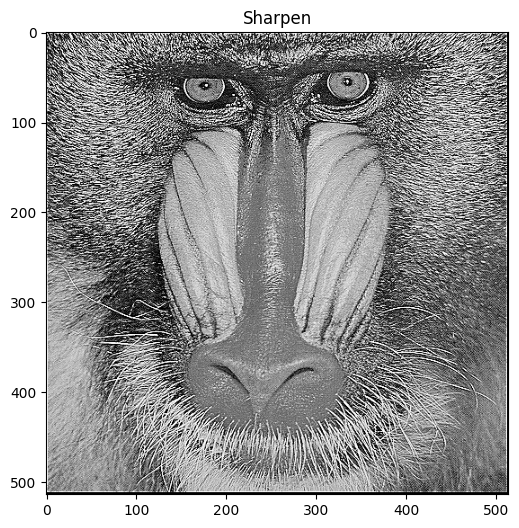

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Kernel sharpening
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

hasil = convolution2d(img_gray, kernel_sharpen, 1, 2)

plt.figure(figsize=(6, 6))
plt.imshow(np.clip(hasil, 0, 255), cmap='gray', vmin=0, vmax=255)
plt.title('Sharpen')
plt.show()


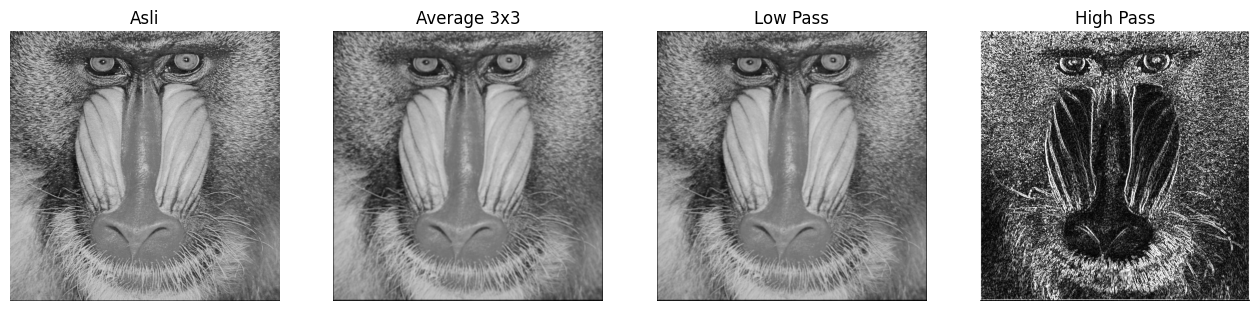

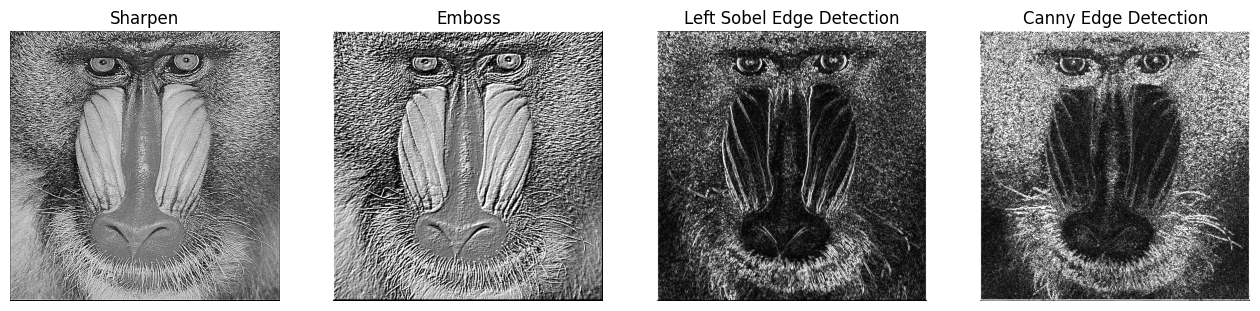

In [ ]:
def tampil_grid(daftar_hasil, daftar_judul, kolom=3, ukuran=5):
    baris = math.ceil(len(daftar_hasil) / kolom)
    plt.figure(figsize=(ukuran * kolom, ukuran * baris))
    for i in range(len(daftar_hasil)):
        plt.subplot(baris, kolom, i + 1)
        plt.imshow(np.clip(daftar_hasil[i], 0, 255), cmap='gray', vmin=0, vmax=255)
        plt.title(daftar_judul[i])
        plt.axis('off')
    plt.show()

# Daftar kernel dari modul
kernel_average  = np.ones((3, 3)) / 9
kernel_lowpass  = np.array([[1, 1, 1],
                            [1, 4, 1],
                            [1, 1, 1]]) / 12
kernel_highpass = np.array([[-1, 0, 1],
                            [-1, 0, 3],
                            [-3, 0, 1]])
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])
kernel_emboss   = np.array([[-2, -1, 0],
                            [-1,  1, 1],
                            [ 0,  1, 2]])
kernel_sobel_kiri = np.array([[1, 0, -1],
                              [2, 0, -2],
                              [1, 0, -1]])
kernel_canny = np.array([[-1, -1, -1],
                              [-1,  8, -1],
                              [-1, -1, -1]])

average  = convolution2d(img_gray, kernel_average, 1, 2)
lowpass  = convolution2d(img_gray, kernel_lowpass, 1, 2)
highpass = np.abs(convolution2d(img_gray, kernel_highpass, 1, 2))
sharpen = convolution2d(img_gray, kernel_sharpen, 1, 2)
emboss   = convolution2d(img_gray, kernel_emboss, 1, 2)
sobel    = np.abs(convolution2d(img_gray, kernel_sobel_kiri, 1, 2))
canny  = np.abs(convolution2d(img_gray, kernel_canny, 1, 2))

tampil_grid([img_gray, average, lowpass, highpass],
            ['Asli', 'Average 3x3', 'Low Pass', 'High Pass'], kolom=4, ukuran=4)

tampil_grid([sharpen, emboss, sobel, canny],
            ['Sharpen', 'Emboss', 'Left Sobel Edge Detection', 'Canny Edge Detection'], kolom=4, ukuran=4)


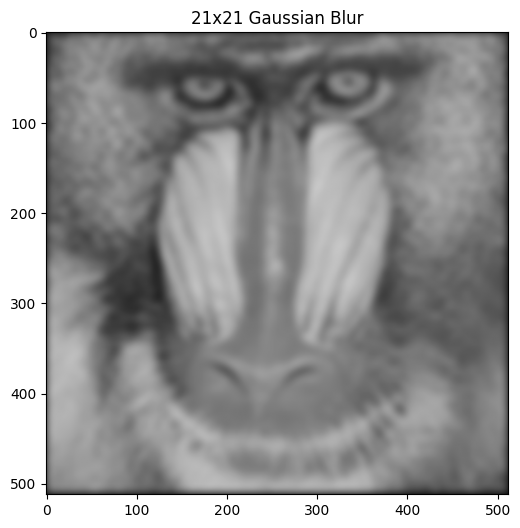

In [ ]:
# Gaussian blur 21x21
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()

hasil_gauss = convolution2d(img_gray, gauss_kernel, 1, 10)

plt.figure(figsize=(6, 6))
plt.imshow(hasil_gauss, cmap='gray', vmin=0, vmax=255)
plt.title('21x21 Gaussian Blur')
plt.show()

##E. FILTER LIBRARY DAN FILTER MODERN

### Percobaan 1: Gaussian, Sharpen, dan Canny dengan library OpenCV

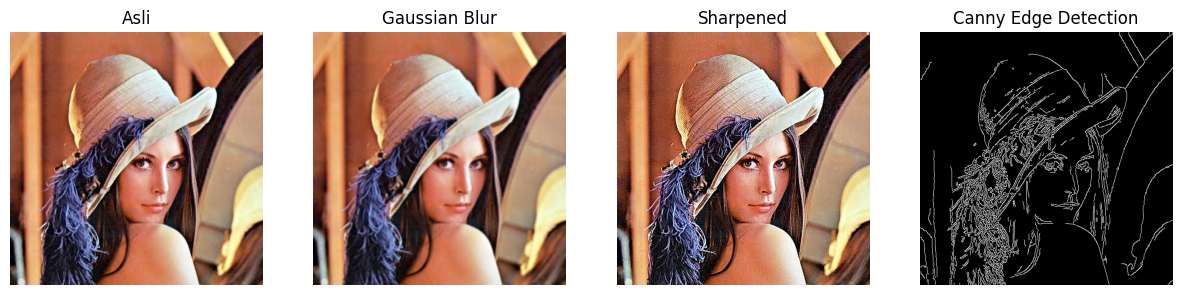

In [ ]:
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:      # grayscale
            plt.subplot(1, len(images), i + 1)
            plt.imshow(img, cmap='gray')
        else:                        # berwarna
            plt.subplot(1, len(images), i + 1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')
img = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])


### Percobaan 2: Filter modern (Bilateral dan Edge Preserving)

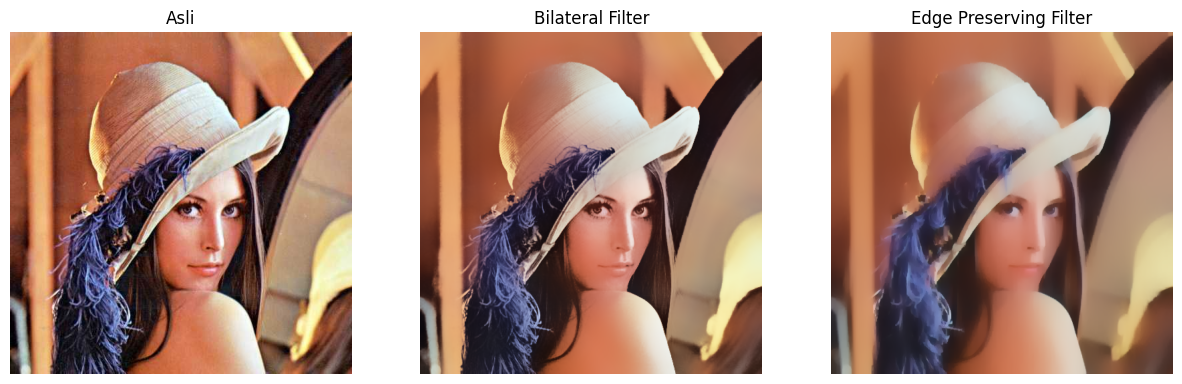

In [ ]:
# Filter modern dari OpenCV
# Bilateral Filter (edge-preserving). Nilai d=50 cukup lambat, tunggu beberapa detik.
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])


### Percobaan 3: Filtering pada CNN (Feature Map)

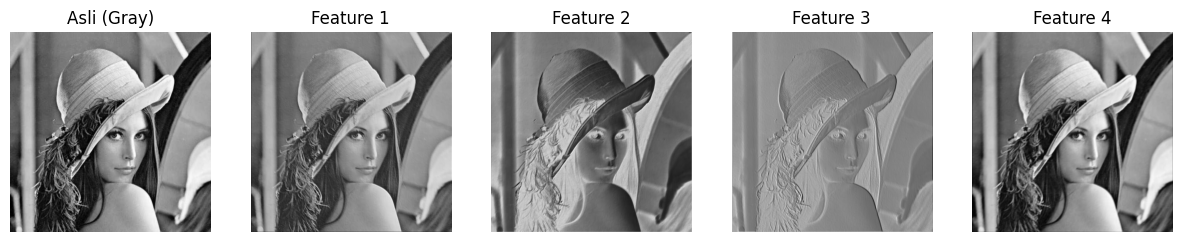

In [ ]:
#Filter Feature Map yang digunakan pada CNN, lakukan running code bagian ini beberapa kali dan perhatikan hasilnya
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])


**Kesimpulan :**
1. Setiap kali kode dijalankan, feature map berubah-ubah karena bobot 4 filter 3x3 dibuat acak setiap model baru dibuat.
2. Tiap feature map adalah hasil konvolusi citra dengan satu kernel, jadi CNN pada dasarnya melakukan hal yang sama dengan yang kita lakukan manual di praktikum D. Kadang hasilnya mirip blur, kadang mirip deteksi tepi, kadang hanya berubah lebih terang/gelap.
3. Bedanya dengan filter manual adalah filter manual dirancang manusia, sedangkan filter CNN dipelajari dari data.


### Percobaan 4: Efek Beauty dan Vintage

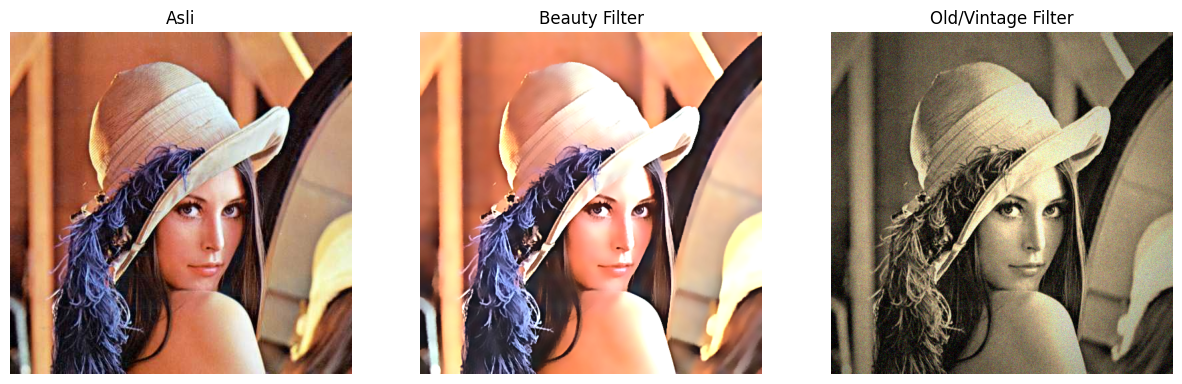

In [ ]:
# =====================
# 1. Beauty Filter
# =====================
# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2   # contrast
beta = 15     # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# =====================
# 2. Old/Vintage Filter
# =====================
# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:, :, i] = vignette[:, :, i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img], ["Asli", "Beauty Filter", "Old/Vintage Filter"])

### Percobaan 5: Filter Anime / Cartoon

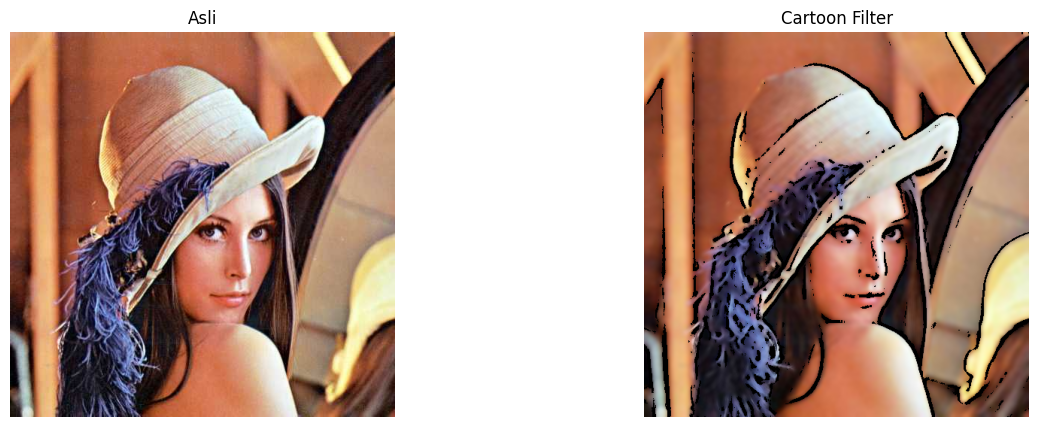

In [ ]:
#Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])


### Percobaan 6: Filter Malam

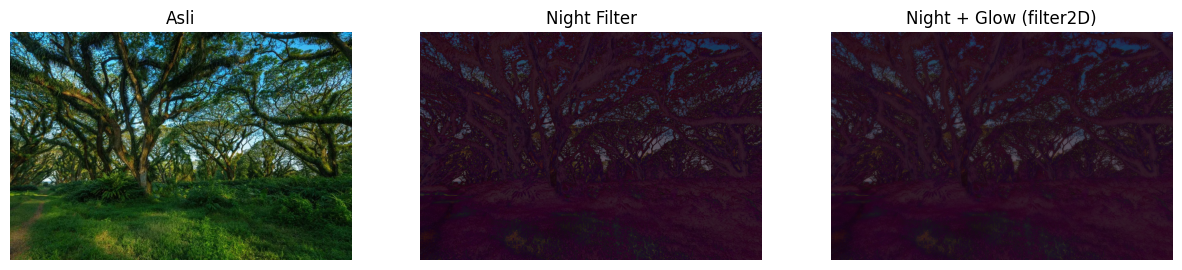

In [ ]:
#Night Filter
img = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/djawatan.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])


### Percobaan 7: Filter Pagi dan Pagi + Kabut

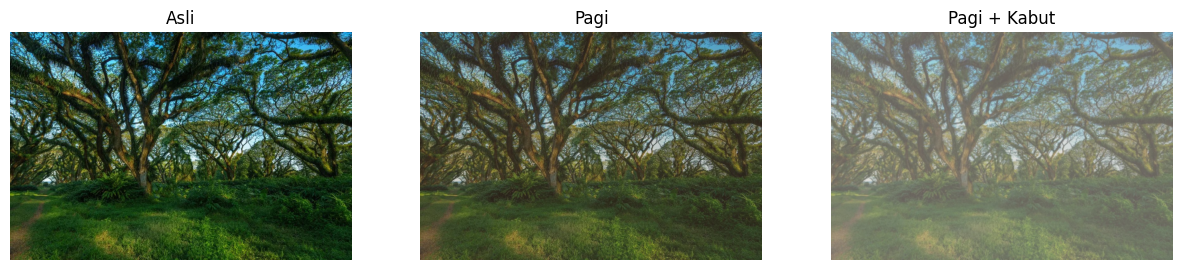

In [ ]:
#Filter Suasana pagi dan Kabut
# =========================
# Step 1: Kurangi kontras & cerahkan
# =========================
alpha = 0.9   # contrast
beta = 20     # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# =========================
# Step 2: Tambahkan warm tone (kemerahan / oranye)
# =========================
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# =========================
# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# =========================
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])


## TUGAS PRAKTIKUM

### 1. Tugas Analisis: Perbandingan Mean Filter (Blur Biasa) vs. Median Filter pada Noise “Salt and Pepper”
**a. Tambahkan noise bintik hitam-putih (Salt and Pepper) ke sebuah citra keabuan (grayscale).**

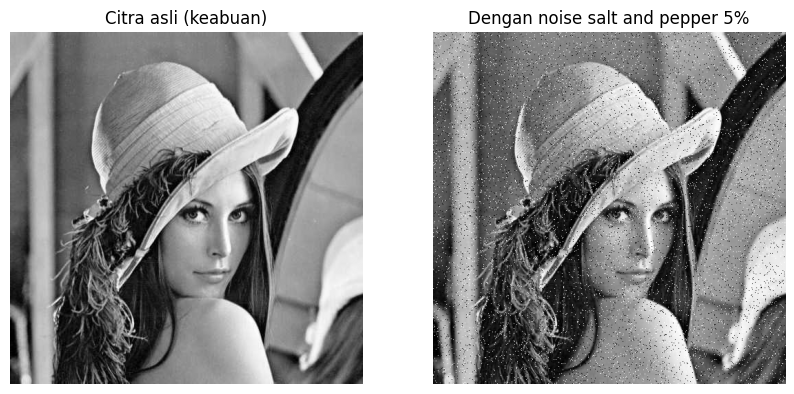

In [ ]:
# Citra keabuan yang akan diberi noise
img = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Fungsi menambah noise salt and pepper
def tambah_salt_pepper(gray, jumlah=0.05):
    hasil = gray.copy()
    acak = np.random.rand(gray.shape[0], gray.shape[1])   # angka acak 0..1 untuk tiap piksel
    hasil[acak < jumlah / 2] = 0                           # separuhnya jadi hitam (pepper)
    hasil[acak > 1 - jumlah / 2] = 255                     # separuhnya jadi putih (salt)
    return hasil

np.random.seed(1)      # supaya noise-nya sama setiap dijalankan
gray_noise = tambah_salt_pepper(img_gray, 0.05)

show_side_by_side([img_gray, gray_noise], ['Citra asli (keabuan)', 'Dengan noise salt and pepper 5%'], figsize=(10, 5))


**Terapkan Mean Filter(3 x 3) dan Median Filter (3 x 3).**

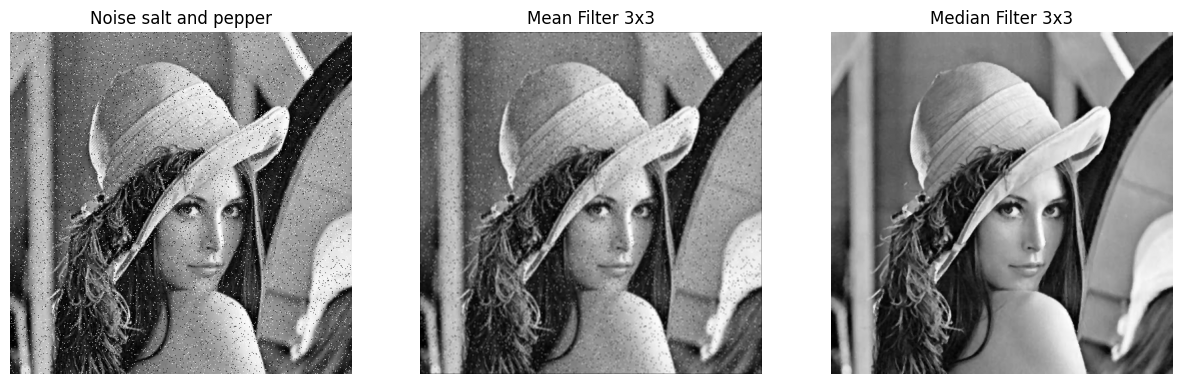

In [ ]:
# Mean filter 3x3: tiap piksel diganti RATA-RATA 9 piksel di sekitarnya
kernel_mean = np.ones((3, 3)) / 9
hasil_mean = convolution2d(gray_noise, kernel_mean, 1, 1)

# Median filter 3x3: tiap piksel diganti NILAI TENGAH dari 9 piksel di sekitarnya
def median_filter_3x3(gray):
    tinggi, lebar = gray.shape
    # tambahkan bingkai 1 piksel dengan menyalin piksel pinggir
    padded = np.pad(gray, 1, mode='edge')
    hasil = np.zeros((tinggi, lebar))
    for y in range(tinggi):
        for x in range(lebar):
            jendela = padded[y:y + 3, x:x + 3]
            hasil[y, x] = np.median(jendela)
    return hasil

hasil_median = median_filter_3x3(gray_noise)

show_side_by_side([gray_noise, hasil_mean, hasil_median],
                  ['Noise salt and pepper', 'Mean Filter 3x3', 'Median Filter 3x3'], figsize=(15, 5))


**Jawaban Tugas 1c:**

- Mean filter mengambil rata-rata sembilan piksel. Piksel rusak bernilai ekstrem (0 atau 255) ikut dijumlahkan, sehingga rata-ratanya ikut tertarik. Akibatnya noise tidak hilang, hanya menyebar menjadi bercak abu-abu yang lebih lebar dan samar, dan tepi objek ikut menjadi kabur. Pada contoh angka di atas, rata-ratanya menjadi sekitar 67 padahal piksel normal bernilai sekitar 50.
- Median filter mengurutkan sembilan piksel lalu mengambil nilai tengah. Piksel rusak (0 atau 255) selalu berada di ujung urutan sehingga tidak pernah terpilih selama noise di jendela itu sedikit. Hasilnya piksel rusak diganti nilai wajar dari tetangganya.
- Jadi median lebih cocok untuk salt and pepper karena noise jenis ini berupa nilai ekstrem yang jarang tapi sangat besar (outlier), dan median kebal terhadap outlier sedangkan rata-rata sangat peka. Median juga menjaga tepi lebih tajam.


###2. Tugas Evaluasi: Pemilihan Ukuran Kernel terbaik untuk Menajamkan Citra (Sharpening)
**a. Buat kernel penajaman (Sharpening Kernel) ukuran 3 x 3 dan 5 x 5.**

In [23]:
# Kernel sharpening 3x3
kernel_3x3 = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

# Kernel sharpening 5x5
kernel_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
])

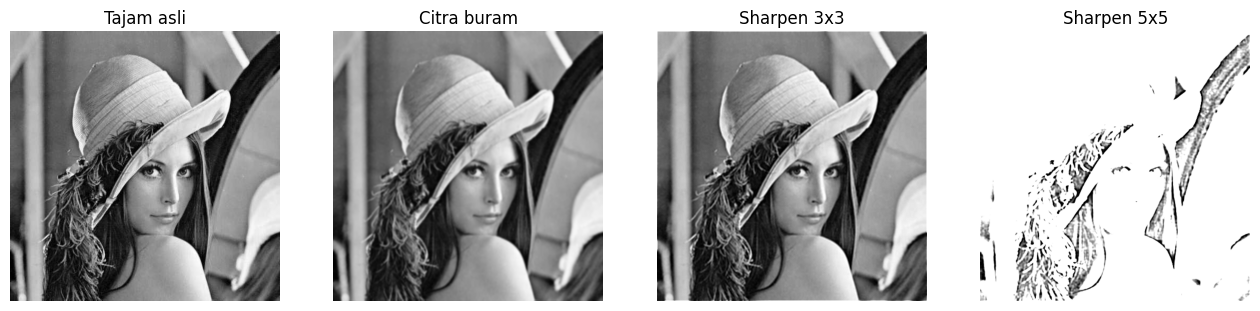

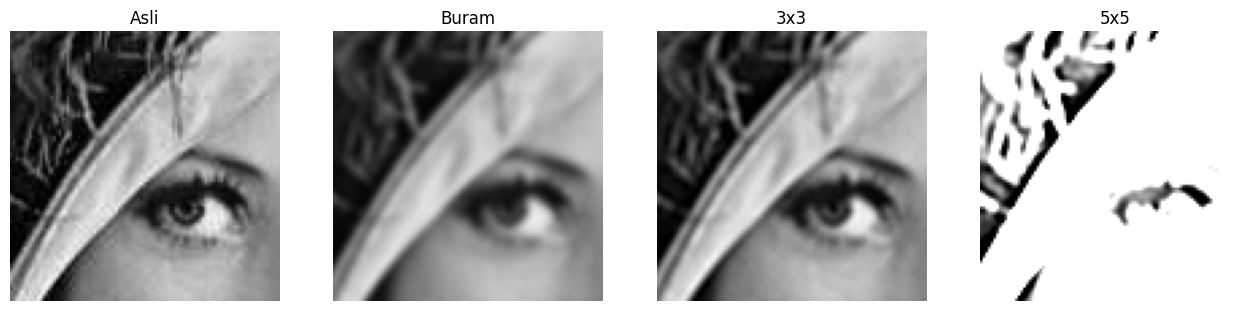

In [29]:
img = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
buram = cv.GaussianBlur(img_gray, (5, 5), 1.5)

# Buat noise halus untuk pengujian
np.random.seed(2)
noise_halus = np.random.normal(0, 3, buram.shape)

# Batasi nilai agar tetap 0-255
buram_noise = np.clip(buram.astype(np.float64) + noise_halus, 0, 255).astype(np.uint8)

# Terapkan kernel sharpening
hasil_k3 = convolution2d(buram, kernel_3x3, 1, 1)
hasil_k5 = convolution2d(buram, kernel_5x5, 1, 2)

tampil_grid(
    [img_gray, buram, hasil_k3, hasil_k5],
    ['Tajam asli', 'Citra buram', 'Sharpen 3x3', 'Sharpen 5x5'],
    kolom=4,
    ukuran=4
)

# Zoom bagian kecil
potongan = (slice(200, 300), slice(200, 300))

tampil_grid(
    [
        img_gray[potongan],
        buram[potongan],
        hasil_k3[potongan],
        hasil_k5[potongan]
    ],
    ['Asli', 'Buram', '3x3', '5x5'],
    kolom=4,
    ukuran=4
)

In [32]:
# ============================
# EVALUASI HASIL SHARPENING
# ============================

# 1. Kejelasan tepi menggunakan Variance of Laplacian
tepi_buram = cv.Laplacian(buram, cv.CV_64F).var()
tepi_k3 = cv.Laplacian(hasil_k3, cv.CV_64F).var()
tepi_k5 = cv.Laplacian(hasil_k5, cv.CV_64F).var()

# 2. Noise / distortion
noise_k3 = np.mean(np.abs(
    hasil_k3.astype(np.float64) - buram.astype(np.float64)
))

noise_k5 = np.mean(np.abs(
    hasil_k5.astype(np.float64) - buram.astype(np.float64)
))

print("=== EVALUASI SHARPENING ===")
print(f"Kejelasan tepi citra buram : {tepi_buram:.2f}")
print(f"Kejelasan tepi kernel 3x3  : {tepi_k3:.2f}")
print(f"Kejelasan tepi kernel 5x5  : {tepi_k5:.2f}")

print(f"\nNoise/Distortion kernel 3x3 : {noise_k3:.2f}")
print(f"Noise/Distortion kernel 5x5 : {noise_k5:.2f}")

=== EVALUASI SHARPENING ===
Kejelasan tepi citra buram : 31.43
Kejelasan tepi kernel 3x3  : 841.62
Kejelasan tepi kernel 5x5  : 29822.35

Noise/Distortion kernel 3x3 : 4.19
Noise/Distortion kernel 5x5 : 862.75


**Jawaban Tugas 2c:**
Berdasarkan hasil pengujian, kedua kernel 3×3 dan 5×5 mampu meningkatkan ketajaman citra yang sebelumnya buram. Kernel 5×5 menghasilkan penajaman tepi yang lebih kuat, tetapi juga cenderung menghasilkan noise dan distorsi yang lebih besar. Sementara itu, kernel 3×3 memberikan penajaman yang lebih seimbang dengan tingkat noise yang lebih rendah.

Dengan mempertimbangkan kejelasan tepi dan kadar noise, kernel 3×3 lebih optimal untuk penggunaan sehari-hari karena mampu memperjelas detail citra tanpa menghasilkan distorsi yang berlebihan. Kernel 5×5 lebih sesuai jika diperlukan penajaman yang lebih kuat dan peningkatan noise masih dapat ditoleransi.

###Tugas Kreasi: Filter Kartun Sederhana
**a. Buatlah sebuah fungsi kustom bernama kartun(image) yang menggabungkan:**
* Penghalusan warna menggunakan **Bilateral Filter** agar area warna menjadi rata.
* Deteksi garis tepi menggunakan **Adaptive Thresholding** atau **Canny Edge**.
* Penggabungan (kombinasi) keduanya menggunakan operasi logika/perkalian piksel.

In [33]:
def kartun(image):
    # Langkah 1: penghalusan warna dengan bilateral filter
    # diulang beberapa kali supaya area warna semakin rata (efek "cat")
    warna = image.copy()
    for i in range(3):
        warna = cv.bilateralFilter(warna, d=9, sigmaColor=75, sigmaSpace=75)

    # Langkah 2: deteksi garis tepi dengan adaptive thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray = cv.medianBlur(gray, 7)                       # haluskan dulu agar garisnya bersih
    garis = cv.adaptiveThreshold(gray, 255,
                                 cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, 9, 9)
    # garis = 0 (hitam) di tepi objek, 255 (putih) di area lain

    # Langkah 3: gabungkan warna dan garis
    # garis diubah jadi 3 kanal supaya bisa dikalikan dengan citra berwarna
    garis_3kanal = cv.cvtColor(garis, cv.COLOR_GRAY2BGR)
    hasil = cv.bitwise_and(warna, garis_3kanal)         # operasi logika AND per piksel
    return hasil


**b. Tampilkan hasil citra asli dengan citra efek kartun bersebelahan.**

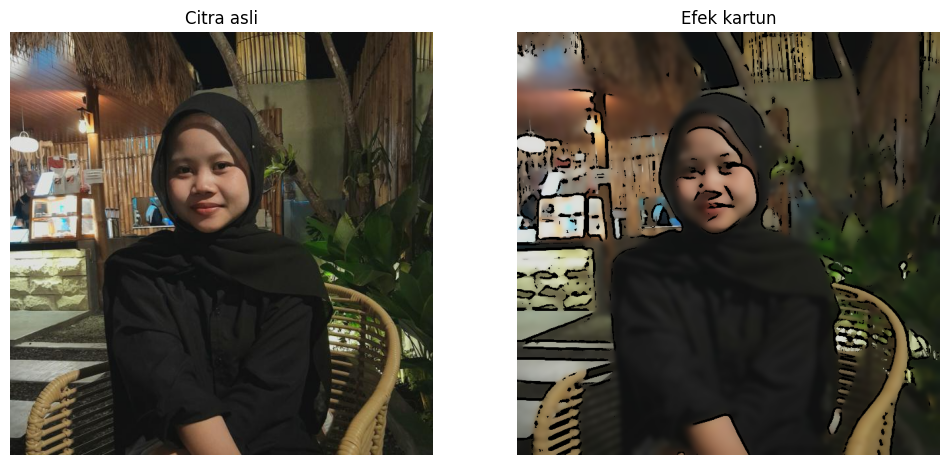

In [35]:
foto = cv.imread('foto.jpeg')
hasil_kartun = kartun(foto)

show_side_by_side([foto, hasil_kartun], ['Citra asli', 'Efek kartun'], figsize=(12, 6))